Mathematical Formulation
Sets:

- $  N  $: Set of selected high-priority customers (after pre-processing)
- $  N_0 = N \cup \{0\}  $: Set of all nodes, where 0 is the depot
- $  K = \{1, 2, \dots, m\}  $: Set of homogeneous drones

Parameters:

- $  d_{ij}  $: Euclidean distance between nodes $  i  $ and $  j  $
- $  e_{ij}  $: Energy consumption for traveling from $  i  $ to $  j  $
- $  q_i  $: Demand (payload) of customer $  i \in N  $
- $  p_i  $: Profit/urgency score of customer $  i  $ (used in pre-processing)
- $  B  $: Initial battery capacity of each drone (one charge per drone per day)
- $  Q  $: Maximum payload capacity of each drone
- $  M  $: Sufficiently large constant (Big-M)
- $  \lambda  $: Small positive weight for the secondary objective (energy minimization)

Decision Variables:

- $  x_{ijk} \in \{0,1\}  $: Binary variable equal to 1 if drone $  k  $ travels directly from node $  i  $ to node $  j  $
- $  u_{ik} \geq 0  $: Cumulative payload carried by drone $  k  $ upon arrival at node $  i  $
- $  b_{ik} \geq 0  $: Remaining battery of drone $  k  $ upon arrival at node $  i  $

Objective Function:
$$\max \quad \sum_{i \in N} p_i \ - \ \lambda \sum_{k \in K} \sum_{i \in N_0} \sum_{j \in N_0} e_{ij} \, x_{ijk}$$

Constraints
1. Each Customer in $  N  $ Served Exactly Once (Updated according to your pre-processing)
$$\sum_{k \in K} \sum_{j \in N_0} x_{ijk} = 1 \quad \forall i \in N$$
2. Flow Conservation
$$\sum_{i \in N_0} x_{ijk} = \sum_{j \in N_0} x_{jik} \quad \forall j \in N_0, \ \forall k \in K$$

3. Battery Constraints (One single charge per drone per day – No recharging)

Initial battery at the beginning:$$b_{0k} = B \quad \forall k \in K$$
Battery consumption on each arc:$$b_{ik} - e_{ij} \cdot x_{ijk} \geq b_{jk} - M(1 - x_{ijk}) \quad \forall i,j \in N_0, \ \forall k \in K$$
Battery limits:$$0 \leq b_{ik} \leq B \quad \forall i \in N_0, \ \forall k \in K$$

4. Payload Constraints (Delivery with unloading at customers + reloading at depot)

Payload update (delivery style):$$u_{ik} - q_j \geq u_{jk} - M(1 - x_{ijk}) \quad \forall i \in N_0, \ j \in N, \ \forall k \in K$$
Payload capacity limit:$$0 \leq u_{ik} \leq Q \quad \forall i \in N_0, \ \forall k \in K$$
Payload reset when returning to depot (reload):$$u_{0k} = 0 \quad \forall k \in K$$

5. Variable Domains

- $  x_{ijk} \in \{0,1\}  $
- $  u_{ik} \geq 0  $, $  b_{ik} \geq 0  $

In [63]:
import numpy as np
import pandas as pd
from pulp import *
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Tuple, Optional
import time
import copy
from collections import deque
import warnings
warnings.filterwarnings('ignore')
 
# Set random seed for reproducibility
np.random.seed(42)
 
# Plotting configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")


In [84]:
class ProblemConfig:
    """Configuration class for drone delivery problem parameters"""
    
    def __init__(self):
        # Fleet parameters
        self.num_drones = 2  # Number of available drones (m)
        self.battery_capacity = 100.0  # Battery capacity B (energy units)
        self.payload_capacity = 10.0  # Payload capacity Q (kg)
        
        # Energy model parameters (Dorling et al. 2016 linear model)
        self.alpha = 0.5  # Energy per kg per km (Wh/kg/km)
        self.beta = 2.0   # Base energy per km (Wh/km)
        self.drone_mass = 3.0  # Base drone mass (kg)
        self.battery_mass = 1.0  # Battery mass (kg)
        
        # TOP parameters
        self.lambda_weight = 0.05  # Weight for energy penalty in objective
        
        # Multi-trip parameters
        self.max_trips_per_drone = 3  # Maximum trips per drone
        
        # Branch & Bound parameters
        self.bnb_time_limit = 300  # seconds (5 minutes)
        self.bnb_gap_tolerance = 0.05  # 5% optimality gap

        self.no_fly_zones = [
            (25.0, 25.0, 8.0),   # Example: circle at (25,25) with 8km radius
            (40.0, 15.0, 6.0),   # Another forbidden area
            
        ]
        
    def energy_consumption(self, distance: float, payload_mass: float) -> float:
        """
        Calculate energy consumption using linear model
        E_ij = (α * m_total + β) * d_ij
        
        Args:
            distance: Distance traveled (km)
            payload_mass: Current payload mass (kg)
            
        Returns:
            Energy consumed (Wh)
        """
        total_mass = self.drone_mass + self.battery_mass + payload_mass
        return (self.alpha * total_mass + self.beta) * distance
    
    def __repr__(self):
        return f"ProblemConfig(drones={self.num_drones}, B={self.battery_capacity}, Q={self.payload_capacity})"

In [85]:
config = ProblemConfig()
print(f"✓ Problem configuration created: {config}")

✓ Problem configuration created: ProblemConfig(drones=2, B=100.0, Q=10.0)


In [86]:
class InstanceGenerator:
    """Generate drone delivery problem instances"""
    
    def __init__(self, config: ProblemConfig):
        self.config = config
        
    def generate_instance(self, 
                         num_customers: int,
                         area_size: Tuple[float, float] = (50, 50),
                         urgency_distribution: str = 'mixed') -> Dict:
        """
        Generate a problem instance
        
        Args:
            num_customers: Number of customers to generate
            area_size: (width, height) of service area in km
            urgency_distribution: 'uniform', 'high_priority', or 'mixed'
            
        Returns:
            Dictionary containing instance data
        """
        # Generate depot at center
        depot_x = area_size[0] / 2
        depot_y = area_size[1] / 2
        
        # Generate customer locations (avoid depot vicinity) AND ensure battery-feasible round trip
        # This is required if later you enforce "all selected customers must be served" under battery B.
        customers_x = []
        customers_y = []

        # Conservative payload used for reachability screening (helps avoid generating impossible instances)
        payload_screen = 0.6 * self.config.payload_capacity

        for _ in range(num_customers):
            attempts = 0
            while True:
                attempts += 1
                if attempts > 5000:
                    raise RuntimeError(
                        "Could not generate battery-feasible customers. Increase B, reduce area_size, or relax screening."
                    )

                x = np.random.uniform(0, area_size[0])
                y = np.random.uniform(0, area_size[1])

                # Ensure minimum distance from depot (2 km)
                dist_to_depot = np.sqrt((x - depot_x) ** 2 + (y - depot_y) ** 2)
                if dist_to_depot <= 2.0:
                    continue

                # Battery-feasible necessary condition: depot -> customer -> depot within one charge
                e_out = self.config.energy_consumption(dist_to_depot, payload_screen)
                e_back = self.config.energy_consumption(dist_to_depot, payload_screen)
                if e_out + e_back > self.config.battery_capacity:
                    continue

                customers_x.append(x)
                customers_y.append(y)
                break
        
        # Generate demands (package weights) - realistic distribution
        # Most packages are 1-5 kg, some heavier ones
        demands = np.random.gamma(shape=2.0, scale=1.5, size=num_customers)
        demands = np.clip(demands, 0.5, 8.0)  # Between 0.5 and 8 kg
        
        # Generate urgency/profit scores based on distribution
        if urgency_distribution == 'uniform':
            urgencies = np.random.uniform(1, 10, num_customers)
        elif urgency_distribution == 'high_priority':
            # More high-urgency customers (medicine, urgent packages)
            urgencies = np.random.choice([8, 9, 10], size=num_customers, p=[0.3, 0.4, 0.3])
            # Add some medium priority
            mask = np.random.rand(num_customers) < 0.3
            urgencies[mask] = np.random.uniform(4, 7, mask.sum())
        else:  # mixed
            # Realistic distribution: few very urgent, many medium, some low
            urgencies = np.random.choice(
                [10, 9, 8, 6, 5, 3],
                size=num_customers,
                p=[0.1, 0.15, 0.2, 0.3, 0.15, 0.1]
            )
        
        # Calculate distance matrix (Euclidean)
        n = num_customers
        all_x = [depot_x] + customers_x
        all_y = [depot_y] + customers_y

        distance_matrix = np.zeros((n + 1, n + 1))
        energy_matrix = np.zeros((n + 1, n + 1))
        feasible_arc = np.ones((n + 1, n + 1), dtype=bool)   # True = allowed

        avg_payload = np.mean(demands)


        for i in range(n + 1):
            for j in range(n + 1):
                if i == j:
                    continue

                dist = np.sqrt((all_x[i] - all_x[j])**2 + (all_y[i] - all_y[j])**2)
                distance_matrix[i, j] = dist
                    

                # Check if this arc intersects any no-fly zone
                if self.intersects_no_fly_zone(all_x[i], all_y[i], all_x[j], all_y[j]):
                    feasible_arc[i, j] = False
                    energy_matrix[i, j] = 0
                else:
                    energy_matrix[i, j] = self.config.energy_consumption(
                        dist, avg_payload * 0.6
                    )
        
    
        
        instance = {
            'num_customers': num_customers,
            'depot': (depot_x, depot_y),
            'customers': list(zip(customers_x, customers_y)),
            'demands': demands.tolist(),
            'urgencies': urgencies.tolist(),
            'distance_matrix': distance_matrix,
            'energy_matrix': energy_matrix,
            'feasible_arc': feasible_arc,
            'area_size': area_size
        }
        
        return instance

    def intersects_no_fly_zone(self, x1: float, y1: float, x2: float, y2: float) -> bool:
        """Return True if the straight line from (x1,y1) to (x2,y2) intersects any no-fly zone"""
        for cx, cy, radius in self.config.no_fly_zones:
            # Simple but effective check: if either point is inside the zone
            if np.sqrt((x1 - cx)**2 + (y1 - cy)**2) <= radius:
                return True
            if np.sqrt((x2 - cx)**2 + (y2 - cy)**2) <= radius:
                return True
            # You can add a more accurate line-circle intersection later if needed
        return False

    
    def visualize_instance(self, instance: Dict, title: str = "Instance Visualization"):
        """Visualize the generated instance"""
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
        
        # Plot 1: Locations with urgency
        depot = instance['depot']
        customers = instance['customers']
        urgencies = instance['urgencies']
        demands = instance['demands']
        
        # Plot depot
        ax1.scatter([depot[0]], [depot[1]], c='red', s=300, marker='s', 
                   label='Depot', edgecolors='black', linewidths=2, zorder=5)
        
        # Plot customers with urgency coloring
        scatter = ax1.scatter(
            [c[0] for c in customers],
            [c[1] for c in customers],
            c=urgencies,
            s=[d * 30 for d in demands],  # Size proportional to demand
            cmap='YlOrRd',
            alpha=0.7,
            edgecolors='black',
            linewidths=1,
            zorder=3
        )
        
        # Add customer labels
        for i, (x, y) in enumerate(customers):
            ax1.annotate(f'{i+1}', (x, y), fontsize=8, ha='center', va='center')
        
        ax1.set_xlabel('X coordinate (km)')
        ax1.set_ylabel('Y coordinate (km)')
        ax1.set_title(f'{title}\n(Size ∝ Demand, Color ∝ Urgency)')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        cbar = plt.colorbar(scatter, ax=ax1)
        cbar.set_label('Urgency Score')
        
        # Plot 2: Customer characteristics
        customer_ids = list(range(1, instance['num_customers'] + 1))
        
        ax2_twin = ax2.twinx()
        
        bar1 = ax2.bar(customer_ids, urgencies, alpha=0.6, color='orange', label='Urgency')
        bar2 = ax2_twin.bar([x + 0.3 for x in customer_ids], demands, 
                           width=0.3, alpha=0.6, color='blue', label='Demand (kg)')
        
        ax2.set_xlabel('Customer ID')
        ax2.set_ylabel('Urgency Score', color='orange')
        ax2_twin.set_ylabel('Demand (kg)', color='blue')
        ax2.set_title('Customer Urgency and Demand')
        ax2.tick_params(axis='y', labelcolor='orange')
        ax2_twin.tick_params(axis='y', labelcolor='blue')
        ax2.grid(True, alpha=0.3)
        
        # Combine legends
        lines1, labels1 = ax2.get_legend_handles_labels()
        lines2, labels2 = ax2_twin.get_legend_handles_labels()
        ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
        
        plt.tight_layout()
        plt.show()
        
        # Print instance statistics
        print(f"\n{'='*60}")
        print(f"INSTANCE STATISTICS")
        print(f"{'='*60}")
        print(f"Number of customers: {instance['num_customers']}")
        print(f"Total demand: {sum(instance['demands']):.2f} kg")
        print(f"Average demand: {np.mean(instance['demands']):.2f} kg")
        print(f"Urgency range: [{min(urgencies)}, {max(urgencies)}]")
        print(f"Average urgency: {np.mean(urgencies):.2f}")
        print(f"Max distance from depot: {np.max(instance['distance_matrix'][0, 1:]):.2f} km")
        print(f"Min distance from depot: {np.min(instance['distance_matrix'][0, 1:]):.2f} km")
        print(f"{'='*60}\n")
 

In [87]:
generator = InstanceGenerator(config)
print("✓ Instance generator created")

✓ Instance generator created


Generating SMALL instance (5 customers)...


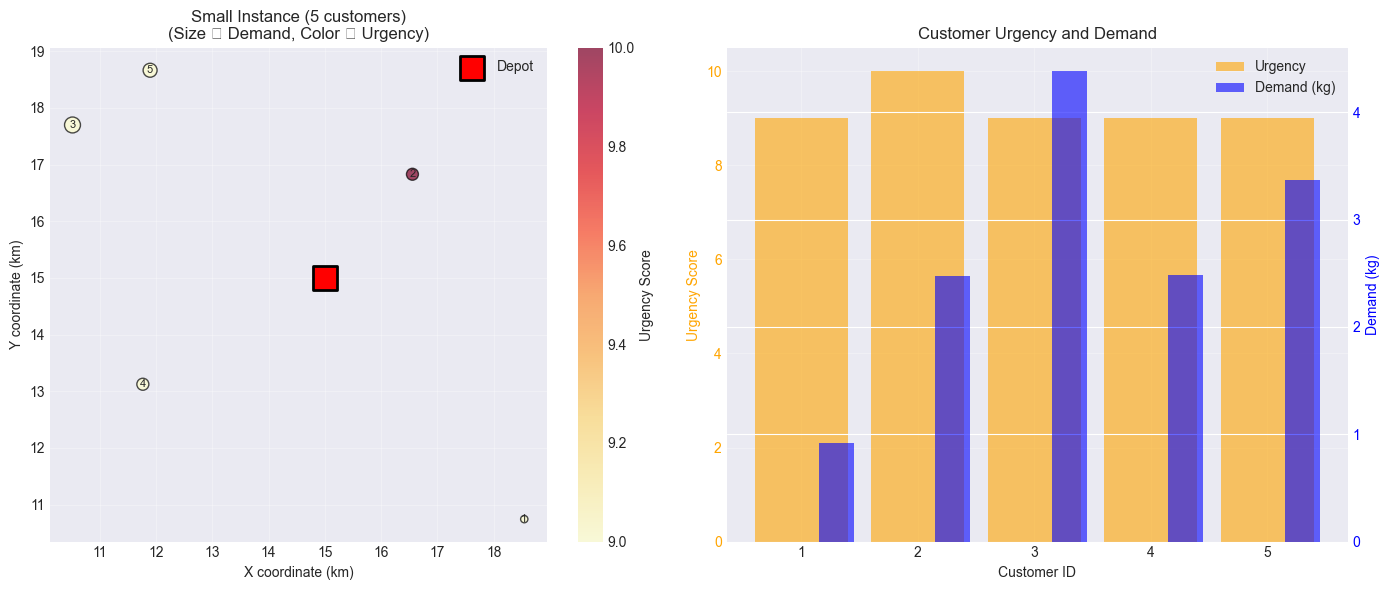


INSTANCE STATISTICS
Number of customers: 5
Total demand: 13.63 kg
Average demand: 2.73 kg
Urgency range: [9, 10]
Average urgency: 9.20
Max distance from depot: 5.54 km
Min distance from depot: 2.40 km


Generating MEDIUM instance (10 customers)...


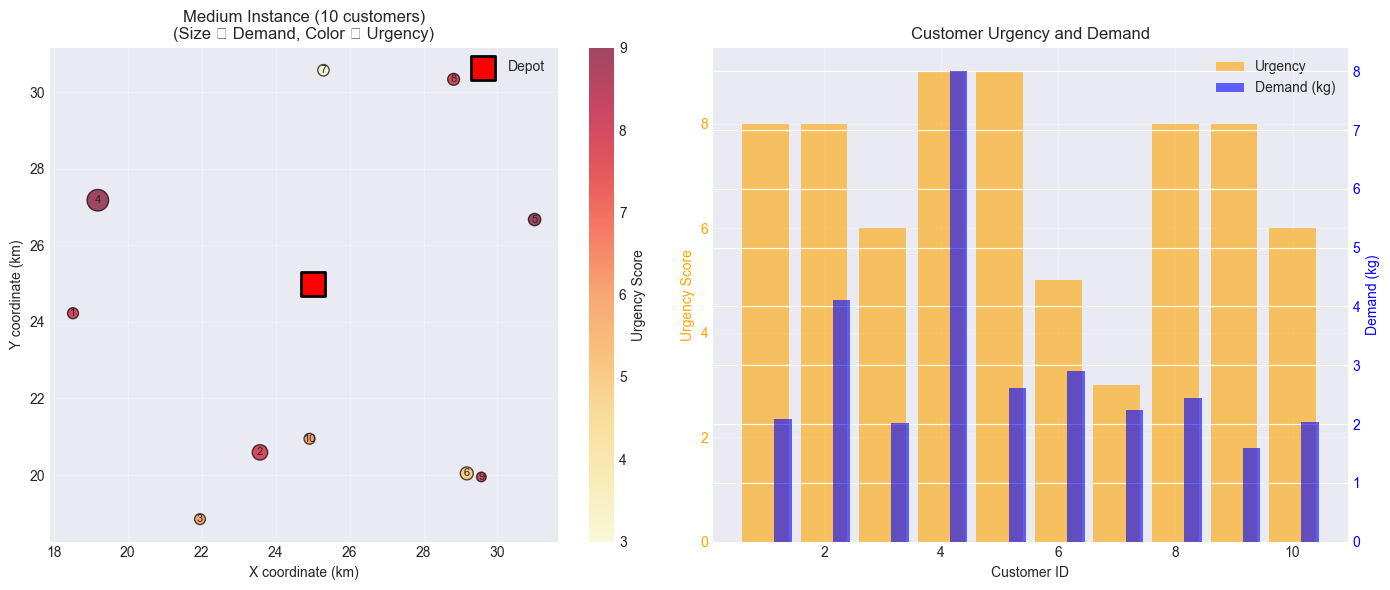


INSTANCE STATISTICS
Number of customers: 10
Total demand: 30.01 kg
Average demand: 3.00 kg
Urgency range: [3, 9]
Average urgency: 7.00
Max distance from depot: 6.86 km
Min distance from depot: 4.05 km


✓ Sample instances generated and stored


In [88]:
# Small instance for testing (5 customers)
print("Generating SMALL instance (5 customers)...")
small_instance = generator.generate_instance(
    num_customers=5,
    area_size=(30, 30),
    urgency_distribution='mixed'
)
generator.visualize_instance(small_instance, "Small Instance (5 customers)")
 
# Medium instance (10 customers)
print("\nGenerating MEDIUM instance (10 customers)...")
medium_instance = generator.generate_instance(
    num_customers=10,
    area_size=(50, 50),
    urgency_distribution='mixed'
)
generator.visualize_instance(medium_instance, "Medium Instance (10 customers)")
 
# Store instances for later use
instances = {
    'small': small_instance,
    'medium': medium_instance
}
 
print("\n✓ Sample instances generated and stored")

In [89]:
"""
Pre-processing step to select high-priority customers
Based on your TOP approach
"""
 
def preprocess_customer_selection(instance: Dict, 
                                  config: ProblemConfig,
                                  k_max: Optional[int] = None) -> Dict:
    """Select top-K customers by urgency **that are feasible to serve**.

    If you later enforce "serve all selected customers exactly once", then this preprocessing
    must remove customers that are individually infeasible (e.g., cannot do depot→i→depot within B).
    """
    n = instance['num_customers']
    urgencies = np.array(instance['urgencies'])
    demands = np.array(instance['demands'])
    e = instance['energy_matrix']
    B = config.battery_capacity
    Q = config.payload_capacity

    # Feasibility filter: each selected customer must at least be reachable in a single out-and-back trip
    # (necessary condition for any serve-all model with depot start/end).
    feasible_mask = np.array([(e[0, i+1] + e[i+1, 0] <= B) and (demands[i] <= Q) for i in range(n)])
    feasible_indices = np.where(feasible_mask)[0]

    if len(feasible_indices) == 0:
        raise ValueError("No customers are individually feasible under current B/Q (round-trip + demand).")

    # If k_max not specified, estimate based on resources
    if k_max is None:
        # crude upper bound based on payload and number of drones (single tour per drone)
        k_max = min(len(feasible_indices), max(1, int(config.num_drones * (Q / max(1e-9, np.mean(demands[feasible_indices]))))))

    # Sort feasible customers by urgency (descending) and pick top-k
    sorted_feasible = feasible_indices[np.argsort(-urgencies[feasible_indices])]
    selected_indices = sorted_feasible[:k_max]
    
    # Create filtered instance
    filtered_instance = copy.deepcopy(instance)
    filtered_instance['num_customers'] = len(selected_indices)
    filtered_instance['customers'] = [instance['customers'][i] for i in selected_indices]
    filtered_instance['demands'] = [instance['demands'][i] for i in selected_indices]
    filtered_instance['urgencies'] = [instance['urgencies'][i] for i in selected_indices]
    
    # Update matrices (keep depot as index 0, reindex customers)
    new_n = len(selected_indices)
    new_distance_matrix = np.zeros((new_n + 1, new_n + 1))
    new_energy_matrix = np.zeros((new_n + 1, new_n + 1))
    
    # Map old indices to new indices (depot remains 0)
    index_mapping = [0] + [i + 1 for i in selected_indices]
    
    for new_i in range(new_n + 1):
        for new_j in range(new_n + 1):
            old_i = index_mapping[new_i]
            old_j = index_mapping[new_j]
            new_distance_matrix[new_i, new_j] = instance['distance_matrix'][old_i, old_j]
            new_energy_matrix[new_i, new_j] = instance['energy_matrix'][old_i, old_j]
    
    filtered_instance['distance_matrix'] = new_distance_matrix
    filtered_instance['energy_matrix'] = new_energy_matrix
    filtered_instance['original_indices'] = selected_indices.tolist()
    filtered_instance['k_max'] = k_max
    
    print(f"\n{'='*60}")
    print(f"PREPROCESSING: Customer Selection (TOP Element)")
    print(f"{'='*60}")
    print(f"Original customers: {n}")
    print(f"Selected customers (K_max): {k_max}")
    print(f"Selection rate: {k_max/n*100:.1f}%")
    print(f"Selected customer IDs: {[i+1 for i in selected_indices]}")
    print(f"Total urgency of selected: {sum(filtered_instance['urgencies']):.1f}")
    print(f"Total urgency of all: {sum(instance['urgencies']):.1f}")
    print(f"Urgency captured: {sum(filtered_instance['urgencies'])/sum(instance['urgencies'])*100:.1f}%")
    print(f"{'='*60}\n")
    
    return filtered_instance
 
 

In [91]:
# Apply preprocessing to medium instance
preprocessed_medium = preprocess_customer_selection(medium_instance, config, k_max=7)
 
print("✓ Preprocessing complete")


PREPROCESSING: Customer Selection (TOP Element)
Original customers: 10
Selected customers (K_max): 7
Selection rate: 70.0%
Selected customer IDs: [np.int64(4), np.int64(5), np.int64(2), np.int64(1), np.int64(8), np.int64(9), np.int64(10)]
Total urgency of selected: 56.0
Total urgency of all: 70.0
Urgency captured: 80.0%

✓ Preprocessing complete


In [92]:
class DroneDeliveryMILP:
    """Arc-based MILP formulation for drone delivery problem"""
    
    def __init__(self, instance: Dict, config: ProblemConfig):
        self.instance = instance
        self.config = config
        self.n = instance['num_customers']  # Number of customers
        self.m = config.num_drones  # Number of drones
        self.model = None
        self.variables = {}
        
    def build_model(self):
        """Arc-Based MILP (serve-all selected customers) with multi-trip drones.

        We model each possible trip as its own vehicle: V = num_drones * max_trips_per_drone.
        Each trip starts/ends at the depot with a full battery, which matches the "no recharging mid-route"
        assumption while still allowing multiple depot returns per drone (across trips).
        """
        R = int(getattr(self.config, 'max_trips_per_drone', 1))
        V_count = self.m * R
        print(f"Building MILP model for {self.n} customers, {self.m} drones, up to {R} trips/drone (V={V_count})...")

        self.model = LpProblem("Drone_Delivery_Optimization", LpMinimize)

        N = list(range(1, self.n + 1))      # customers 1..n
        N0 = [0] + N                        # 0 = depot
        V = list(range(1, V_count + 1))     # trip-vehicles

        e = self.instance['energy_matrix']
        q = [0] + self.instance['demands']  # q[0] = 0
        B = self.config.battery_capacity
        Q = self.config.payload_capacity
        M = 100000.0

        # Decision variables
        x = LpVariable.dicts(
            "x",
            ((i, j, v) for i in N0 for j in N0 if i != j for v in V),
            0,
            1,
            LpBinary,
        )
        # u[(i,v)] = cumulative delivered payload by trip-vehicle v upon arrival at node i
        u = LpVariable.dicts("u", ((i, v) for i in N0 for v in V), 0, Q, LpContinuous)
        # b[(i,v)] = remaining battery upon arrival at node i
        b = LpVariable.dicts("b", ((i, v) for i in N0 for v in V), 0, B, LpContinuous)

        # For subtour elimination / assignment
        visit = LpVariable.dicts("visit", ((i, v) for i in N for v in V), 0, 1, LpBinary)
        t = LpVariable.dicts("t", ((i, v) for i in N for v in V), 0, self.n, LpContinuous)

        self.variables = {'x': x, 'u': u, 'b': b, 'visit': visit, 't': t, 'V': V, 'R': R}

        # Objective: minimize total energy
        self.model += lpSum(e[i][j] * x[(i, j, v)] for i in N0 for j in N0 if i != j for v in V), "Total_Energy"

        # 1) Each customer served exactly once (incoming across all trip-vehicles)
        for i in N:
            self.model += lpSum(x[(j, i, v)] for j in N0 if j != i for v in V) == 1, f"Serve_Customer_{i}"

        # 2) Flow conservation per trip-vehicle (includes depot)
        for j in N0:
            for v in V:
                self.model += (
                    lpSum(x[(i, j, v)] for i in N0 if i != j)
                    == lpSum(x[(j, i, v)] for i in N0 if i != j),
                    f"Flow_Conservation_{j}_{v}",
                )

        # 2b) Depot start/end constraints (each trip-vehicle is a single depot tour)
        for v in V:
            self.model += lpSum(x[(0, j, v)] for j in N) <= 1, f"Depot_Depart_{v}"
            self.model += lpSum(x[(i, 0, v)] for i in N) <= 1, f"Depot_Return_{v}"
            self.model += (
                lpSum(x[(0, j, v)] for j in N) == lpSum(x[(i, 0, v)] for i in N),
                f"Depot_Balance_{v}",
            )

        # 2c) Link visit to x (for each trip-vehicle)
        for i in N:
            for v in V:
                self.model += lpSum(x[(i, j, v)] for j in N0 if j != i) == visit[(i, v)], f"VisitOut_{i}_{v}"
                self.model += lpSum(x[(j, i, v)] for j in N0 if j != i) == visit[(i, v)], f"VisitIn_{i}_{v}"

        # Each customer assigned to exactly one trip-vehicle (strengthening)
        for i in N:
            self.model += lpSum(visit[(i, v)] for v in V) == 1, f"Assign_{i}"

        # 2d) Subtour elimination (MTZ) per trip-vehicle
        for v in V:
            for i in N:
                self.model += t[(i, v)] <= self.n * visit[(i, v)], f"OrderLink_{i}_{v}"
            for i in N:
                for j in N:
                    if i != j:
                        self.model += (
                            t[(i, v)] - t[(j, v)] + self.n * x[(i, j, v)] <= self.n - 1,
                            f"MTZ_{i}_{j}_{v}",
                        )

        # 3) Battery constraints
        for v in V:
            self.model += b[(0, v)] == B, f"Start_Full_Battery_{v}"

        for i in N0:
            for j in N0:
                if i == j:
                    continue
                for v in V:
                    if j != 0:
                        self.model += (
                            b[(j, v)] <= b[(i, v)] - e[i][j] + M * (1 - x[(i, j, v)]),
                            f"Battery_Transit_{i}_{j}_{v}",
                        )
                    else:
                        self.model += (
                            b[(i, v)] >= e[i][0] * x[(i, 0, v)],
                            f"Battery_Return_{i}_{v}",
                        )

        # 4) Payload capacity constraints (cumulative delivered load)
        for v in V:
            self.model += u[(0, v)] == 0, f"Start_Zero_Delivered_{v}"

        for i in N0:
            for j in N:
                if i == j:
                    continue
                for v in V:
                    self.model += (
                        u[(j, v)] >= u[(i, v)] + q[j] - M * (1 - x[(i, j, v)]),
                        f"Payload_Transit_{i}_{j}_{v}",
                    )

        print(f"✓ Model built successfully: {len(self.model.variables())} variables, {len(self.model.constraints)} constraints")
        
    def solve(self, time_limit: int = 300):
        """Solve the MILP model"""
        
        if self.model is None:
            raise ValueError("Model not built. Call build_model() first.")
        
        print(f"\n{'='*60}")
        print(f"SOLVING MILP MODEL")
        print(f"{'='*60}")
        print(f"Solver: PuLP (CBC)")
        print(f"Time limit: {time_limit} seconds")
        
        # Solve with time limit
        start_time = time.time()
        
        # Use CBC solver with time limit
        solver = PULP_CBC_CMD(timeLimit=time_limit, msg=1, gapRel=self.config.bnb_gap_tolerance)
        self.model.solve(solver)
        
        solve_time = time.time() - start_time
        
        print(f"\n{'='*60}")
        print(f"SOLUTION STATUS: {LpStatus[self.model.status]}")
        print(f"{'='*60}")
        print(f"Solve time: {solve_time:.2f} seconds")
        
        if self.model.status == LpStatusOptimal or self.model.status == LpStatusNotSolved:
            obj_value = value(self.model.objective)
            print(f"Objective value: {obj_value:.2f}")
            
            # Extract solution
            solution = self.extract_solution()
            return solution
        else:
            print(f"No solution found!")
            return None
    
    def extract_solution(self) -> Dict:
        """Extract solution from solved model"""
        
        if self.model.status not in [LpStatusOptimal, LpStatusNotSolved]:
            return None
        
        x = self.variables['x']
        b = self.variables['b']
        u = self.variables['u']
        y = self.variables.get('y', {})
        
        # Extract routes from trip-vehicles, then group by drone
        V = self.variables.get('V', list(range(1, self.m + 1)))
        R = int(self.variables.get('R', 1))

        chosen_arcs = {(i, j, v) for (i, j, v), var in x.items() if value(var) is not None and value(var) > 0.5}

        # Build adjacency per trip-vehicle
        out_arc = {v: {} for v in V}
        for (i, j, v) in chosen_arcs:
            out_arc[v][i] = j

        trip_routes = {}
        for v in V:
            if 0 not in out_arc[v]:
                continue
            route = [0]
            current = 0
            max_steps = self.n + 2
            for _ in range(max_steps):
                nxt = out_arc[v].get(current)
                if nxt is None:
                    break
                route.append(nxt)
                current = nxt
                if current == 0:
                    break
            if len(route) > 1:
                trip_routes[v] = route

        # Group trips back to drones
        routes = {k: [] for k in range(1, self.m + 1)}
        for v, route in trip_routes.items():
            drone_id = (v - 1) // R + 1
            routes[drone_id].append(route)
        
        # Calculate metrics from decision variables (ground truth)
        e = self.instance['energy_matrix']
        p = [0] + self.instance['urgencies']

        total_energy = sum(e[i][j] for (i, j, v) in chosen_arcs)

        served_customers = set()
        total_profit = 0.0
        for i in range(1, self.n + 1):
            if any((j, i, v) in chosen_arcs for j in range(0, self.n + 1) if j != i for v in V):
                served_customers.add(i)
                total_profit += p[i]
        
        solution = {
            'routes': routes,
            'total_energy': total_energy,
            'total_profit': total_profit,
            'served_customers': list(served_customers),
            'num_served': len(served_customers),
            'objective_value': value(self.model.objective),
            'solve_status': LpStatus[self.model.status]
        }
        
        return solution
    
    def visualize_solution(self, solution: Dict):
        """Visualize the solution routes"""
        
        if solution is None:
            print("No solution to visualize")
            return
        
        fig, ax = plt.subplots(figsize=(12, 10))
        
        # Get coordinates
        depot = self.instance['depot']
        customers = self.instance['customers']
        
        # Plot depot
        ax.scatter([depot[0]], [depot[1]], c='red', s=400, marker='s',
                  label='Depot', edgecolors='black', linewidths=2, zorder=10)
        
        # Plot customers
        served = solution['served_customers']
        unserved = [i for i in range(1, self.n + 1) if i not in served]
        
        if served:
            served_coords = [customers[i-1] for i in served]
            ax.scatter([c[0] for c in served_coords], [c[1] for c in served_coords],
                      c='green', s=200, alpha=0.7, label='Served', 
                      edgecolors='black', linewidths=1, zorder=5)
        
        if unserved:
            unserved_coords = [customers[i-1] for i in unserved]
            ax.scatter([c[0] for c in unserved_coords], [c[1] for c in unserved_coords],
                      c='gray', s=200, alpha=0.3, label='Unserved',
                      edgecolors='black', linewidths=1, zorder=5)
        
        # Add customer labels
        for i in range(1, self.n + 1):
            x, y = customers[i-1]
            ax.annotate(f'{i}', (x, y), fontsize=10, ha='center', va='center', 
                       fontweight='bold')
        
        # Plot routes
        colors = plt.cm.tab10(np.linspace(0, 1, self.m))
        
        for k, trips in solution['routes'].items():
            if not trips:
                continue
            color = colors[k-1]
            all_coords = [depot] + customers

            for t_idx, route in enumerate(trips, start=1):
                if len(route) <= 1:
                    continue
                for i in range(len(route) - 1):
                    from_idx = route[i]
                    to_idx = route[i + 1]

                    x_coords = [all_coords[from_idx][0], all_coords[to_idx][0]]
                    y_coords = [all_coords[from_idx][1], all_coords[to_idx][1]]

                    ax.plot(
                        x_coords,
                        y_coords,
                        c=color,
                        linewidth=2,
                        alpha=0.7,
                        label=f'Drone {k}' if (t_idx == 1 and i == 0) else '',
                        zorder=3,
                    )

                    ax.annotate(
                        '',
                        xy=(x_coords[1], y_coords[1]),
                        xytext=(x_coords[0], y_coords[0]),
                        arrowprops=dict(arrowstyle='->', color=color, lw=1.5, alpha=0.7),
                    )
        
        ax.set_xlabel('X coordinate (km)', fontsize=12)
        ax.set_ylabel('Y coordinate (km)', fontsize=12)
        ax.set_title(f'Solution Routes\nServed: {solution["num_served"]}/{self.n} | ' +
                    f'Profit: {solution["total_profit"]:.1f} | ' +
                    f'Energy: {solution["total_energy"]:.2f}',
                    fontsize=14, fontweight='bold')
        ax.legend(loc='best', fontsize=10)
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        # Print detailed solution
        print(f"\n{'='*60}")
        print(f"DETAILED SOLUTION")
        print(f"{'='*60}")
        for k, trips in solution['routes'].items():
            if not trips:
                continue
            print(f"\nDrone {k}:")
            e = self.instance['energy_matrix']
            p = [0] + self.instance['urgencies']

            drone_energy = 0.0
            drone_profit = 0.0

            for t_idx, route in enumerate(trips, start=1):
                if len(route) <= 1:
                    continue
                print(f"  Trip {t_idx}: {' → '.join(map(str, route))}")

                route_energy = 0.0
                route_profit = 0.0
                for i in range(len(route) - 1):
                    route_energy += e[route[i]][route[i+1]]
                    if route[i+1] > 0:
                        route_profit += p[route[i+1]]

                drone_energy += route_energy
                drone_profit += route_profit

                print(f"    Energy consumed: {route_energy:.2f}")
                print(f"    Profit collected: {route_profit:.1f}")

            print(f"  Total energy (drone): {drone_energy:.2f}")
            print(f"  Total profit (drone): {drone_profit:.1f}")
        
        print(f"\n{'='*60}")
        print(f"SUMMARY")
        print(f"{'='*60}")
        print(f"Customers served: {solution['num_served']}/{self.n}")
        print(f"Total profit: {solution['total_profit']:.2f}")
        print(f"Total energy: {solution['total_energy']:.2f}")
        print(f"Objective value: {solution['objective_value']:.2f}")
        print(f"{'='*60}\n")
 
 
print("✓ MILP model builder class defined")

✓ MILP model builder class defined



TESTING MILP SOLVER ON SMALL INSTANCE
Building MILP model for 5 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 312 variables, 616 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 60 seconds

SOLUTION STATUS: Optimal
Solve time: 19.21 seconds
Objective value: 151.44


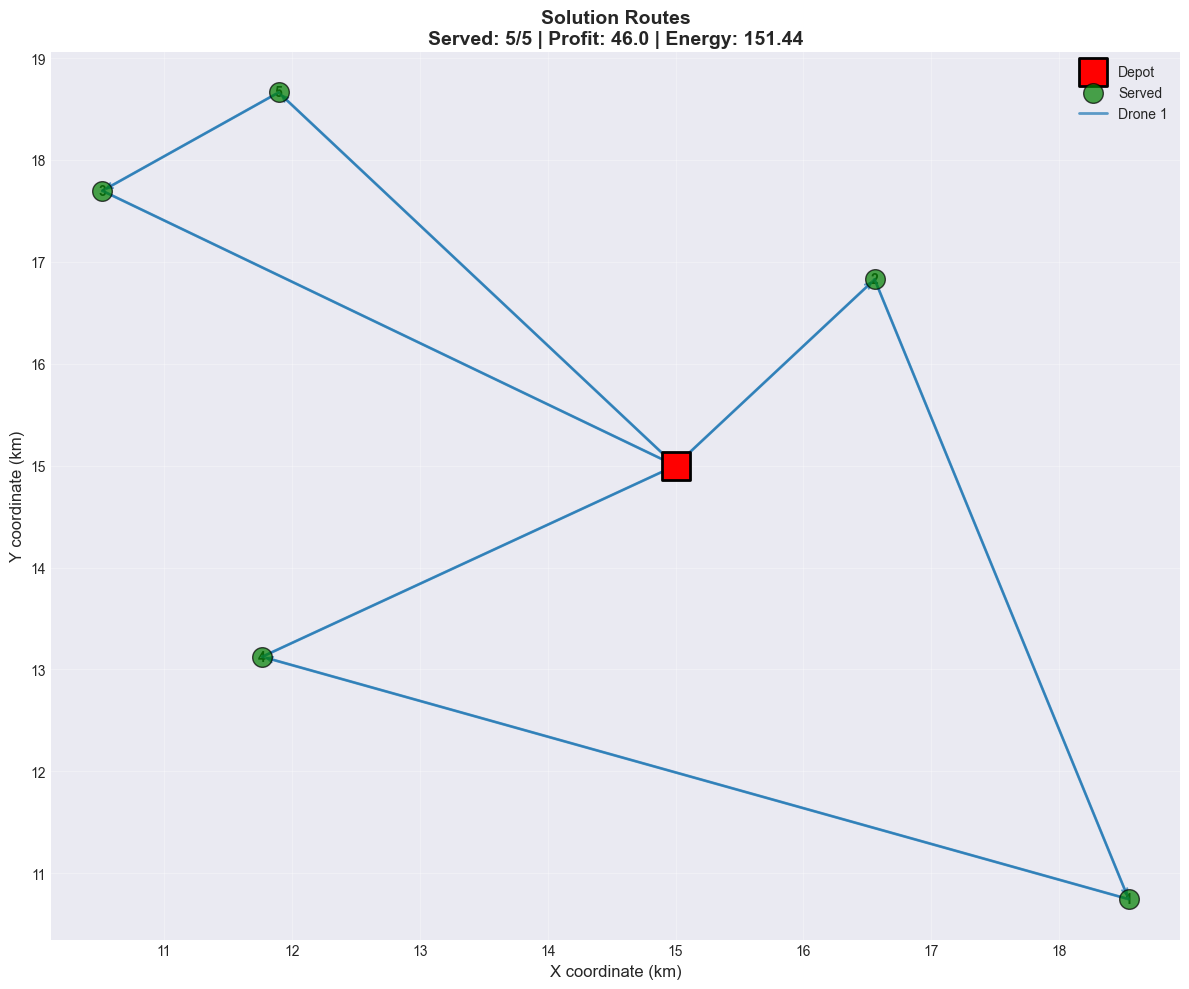


DETAILED SOLUTION

Drone 1:
  Trip 1: 0 → 2 → 1 → 4 → 0
    Energy consumed: 95.00
    Profit collected: 28.0
  Trip 2: 0 → 5 → 3 → 0
    Energy consumed: 56.44
    Profit collected: 18.0
  Total energy (drone): 151.44
  Total profit (drone): 46.0

SUMMARY
Customers served: 5/5
Total profit: 46.00
Total energy: 151.44
Objective value: 151.44



In [93]:
"""
Test the MILP solver on the small instance
"""
 
print("\n" + "="*70)
print("TESTING MILP SOLVER ON SMALL INSTANCE")
print("="*70)
 
# Create and solve model for small instance
milp_small = DroneDeliveryMILP(small_instance, config)
milp_small.build_model()
solution_small = milp_small.solve(time_limit=60)
 
if solution_small:
    milp_small.visualize_solution(solution_small)

In [73]:
"""
Implement nearest neighbor heuristic for initial feasible solution
Used as upper bound in Branch & Bound
"""
 
class NearestNeighborHeuristic:
    """Nearest Neighbor constructive heuristic for drone routing"""
    
    def __init__(self, instance: Dict, config: ProblemConfig):
        self.instance = instance
        self.config = config
        
    def solve(self, prioritize_urgency: bool = True) -> Dict:
        """
        Construct solution using nearest neighbor with urgency priority
        
        Args:
            prioritize_urgency: If True, sort by urgency first
            
        Returns:
            Solution dictionary
        """
        n = self.instance['num_customers']
        customers = list(range(1, n + 1))
        
        # Sort customers by urgency (descending) if prioritized
        if prioritize_urgency:
            urgencies = self.instance['urgencies']
            customers = sorted(customers, key=lambda i: urgencies[i-1], reverse=True)
        
        unvisited = set(customers)
        routes = {k: [] for k in range(1, self.config.num_drones + 1)}
        
        drone_batteries = {k: self.config.battery_capacity for k in range(1, self.config.num_drones + 1)}
        drone_trips = {k: 0 for k in range(1, self.config.num_drones + 1)}
        
        # Greedy assignment
        for customer in customers:
            if customer not in unvisited:
                continue
            
            # Try to assign to a drone
            assigned = False
            
            for k in range(1, self.config.num_drones + 1):
                # Check if can extend current route or start new trip
                current_route = routes[k]
                
                if not current_route or current_route[-1] == 0:
                    # Start new trip from depot
                    if drone_trips[k] >= self.config.max_trips_per_drone:
                        continue
                    
                    # Check energy feasibility: depot -> customer -> depot
                    energy_to = self.instance['energy_matrix'][0][customer]
                    energy_back = self.instance['energy_matrix'][customer][0]
                    
                    if energy_to + energy_back <= drone_batteries[k]:
                        # Feasible
                        routes[k].extend([0, customer] if not current_route else [customer])
                        drone_batteries[k] -= energy_to
                        unvisited.remove(customer)
                        assigned = True
                        break
                else:
                    # Extend current trip
                    last_customer = current_route[-1]
                    
                    # Check energy: current -> customer -> depot
                    energy_to = self.instance['energy_matrix'][last_customer][customer]
                    energy_back = self.instance['energy_matrix'][customer][0]
                    
                    if energy_to + energy_back <= drone_batteries[k]:
                        # Feasible
                        routes[k].append(customer)
                        drone_batteries[k] -= energy_to
                        unvisited.remove(customer)
                        assigned = True
                        break
            
            if not assigned:
                # Cannot assign this customer with current setup
                pass
        
        # Close all routes
        for k in routes:
            if routes[k] and routes[k][-1] != 0:
                routes[k].append(0)
        
        # Calculate solution metrics
        total_energy = 0
        total_profit = 0
        served_customers = []
        
        e = self.instance['energy_matrix']
        p = [0] + self.instance['urgencies']
        
        for k, route in routes.items():
            for i in range(len(route) - 1):
                from_node = route[i]
                to_node = route[i + 1]
                total_energy += e[from_node][to_node]
                
                if to_node > 0 and to_node not in served_customers:
                    served_customers.append(to_node)
                    total_profit += p[to_node]
        
        solution = {
            'routes': routes,
            'total_energy': total_energy,
            'total_profit': total_profit,
            'served_customers': served_customers,
            'num_served': len(served_customers),
            'objective_value': total_profit - self.config.lambda_weight * total_energy
        }
        
        return solution
 
 
print("✓ Nearest Neighbor heuristic defined")

✓ Nearest Neighbor heuristic defined


In [74]:
"""
Test the nearest neighbor heuristic
"""
 
print("\n" + "="*70)
print("TESTING NEAREST NEIGHBOR HEURISTIC")
print("="*70)
 
nn_heuristic = NearestNeighborHeuristic(small_instance, config)
nn_solution = nn_heuristic.solve(prioritize_urgency=True)
 
print(f"\nHeuristic Solution:")
print(f"  Customers served: {nn_solution['num_served']}/{small_instance['num_customers']}")
print(f"  Total profit: {nn_solution['total_profit']:.2f}")
print(f"  Total energy: {nn_solution['total_energy']:.2f}")
print(f"  Objective value: {nn_solution['objective_value']:.2f}")
 
for k, route in nn_solution['routes'].items():
    if len(route) > 0:
        print(f"  Drone {k}: {' → '.join(map(str, route))}")


TESTING NEAREST NEIGHBOR HEURISTIC

Heuristic Solution:
  Customers served: 4/5
  Total profit: 27.00
  Total energy: 164.38
  Objective value: 18.78
  Drone 1: 0 → 1 → 0
  Drone 2: 0 → 3 → 5 → 2 → 0


In [75]:
def generate_drone_instance(n_customers=10, n_drones=2, K_max=None, seed=42):
    """
    Generate a drone delivery instance with pre-processing
    """
    random.seed(seed)
    np.random.seed(seed)
    
    if K_max is None:
        K_max = min(n_customers, 8)   # Limit selected customers for small instances
    
    # Locations: Depot at (0,0), customers in [10,90] area
    depot = np.array([0.0, 0.0])
    locations = np.random.uniform(10, 90, size=(n_customers, 2))
    all_points = np.vstack([depot, locations])  # index 0 = depot
    
    # Distance matrix
    dist = np.zeros((n_customers + 1, n_customers + 1))
    for i in range(n_customers + 1):
        for j in range(n_customers + 1):
            dist[i, j] = np.linalg.norm(all_points[i] - all_points[j])
    
    # Energy matrix (more realistic than distance)
    energy = 1.25 * dist + 2.0
    
    # Demands (kg)
    demands = np.random.uniform(0.8, 4.5, n_customers)
    
    # Urgency / Profit scores
    urgency = np.random.uniform(10, 100, n_customers)
    
    # === Pre-processing: Select top K_max urgent customers ===
    sorted_indices = np.argsort(urgency)[::-1]  # descending order
    selected_idx = sorted_indices[:K_max]       # top K_max customers
    
    N = selected_idx + 1                        # +1 because index 0 is depot
    N.sort()
    
    # Remap to new indices for simplicity (0 = depot, 1 to len(N) = customers)
    n_selected = len(N)
    demand_map = {old+1: demands[old] for old in range(n_customers)}
    urgency_map = {old+1: urgency[old] for old in range(n_customers)}
    
    selected_demands = np.array([demand_map[i] for i in N])
    selected_urgency = np.array([urgency_map[i] for i in N])
    
    instance = {
        'n': n_selected,                    # number of selected customers
        'm': n_drones,
        'dist': dist,
        'energy': energy,
        'demands': selected_demands,
        'urgency': selected_urgency,
        'original_indices': N,              # mapping back to original customers
        'B': 280.0,                         # Battery capacity
        'Q': 12.0,                          # Payload capacity
        'lambda': 0.08,                     # weight for energy
        'locations': all_points,
        'seed': seed
    }
    
    print(f"Instance generated: {n_selected} selected customers out of {n_customers}")
    return instance

In [76]:
class Node:
    def __init__(self, fixed_vars, lp_value, depth=0):
        self.fixed_vars = fixed_vars      # dict of (i,j,k) -> 0 or 1
        self.lp_value = lp_value          # lower bound from LP relaxation
        self.depth = depth
        self.solution = None              # will store integer solution if found

    def __lt__(self, other):
        return self.lp_value < other.lp_value   # for best-first search

In [77]:
def simple_nearest_neighbor_heuristic(instance):
    """Simple heuristic to get upper bound"""
    # Very basic implementation - returns a large number for now
    # You can improve this later
    return instance['energy'].sum() * 0.8   # placeholder

In [79]:
import heapq
import random


def custom_branch_and_bound(instance, time_limit=60, use_best_first=True):
    """
    Simple Custom Branch & Bound Framework for your Drone Problem
    """
    start_time = time.time()
    n = instance['n']
    m = instance['m']
    B = instance['B']
    Q = instance['Q']
    energy = instance['energy']
    
    print("Starting Custom Branch & Bound...")
    
    # Initial Upper Bound from heuristic
    best_ub = simple_nearest_neighbor_heuristic(instance)
    best_solution = None
    
    # Root node
    root = Node(fixed_vars={}, lp_value=0.0, depth=0)
    
    # Use priority queue for Best-First or stack for Depth-First
    if use_best_first:
        pq = []                     # min-heap on lower bound
        heapq.heappush(pq, (0.0, root))
    else:
        stack = deque([root])
    
    nodes_explored = 0
    best_lb = 0.0
    
    while True:
        if time.time() - start_time > time_limit:
            print("Time limit reached!")
            break
            
        if use_best_first:
            if not pq:
                break
            _, current = heapq.heappop(pq)
        else:
            if not stack:
                break
            current = stack.pop()
        
        nodes_explored += 1
        
        # Solve LP relaxation (simplified - in real code use Gurobi/PuLP)
        # For demonstration, we use a dummy LP value
        current_lb = current.lp_value + random.uniform(0, 10)
        
        # Pruning by bound
        if current_lb >= best_ub:
            continue
            
        # In real implementation: solve LP relaxation here with fixed_vars
        
        # Simulate finding an integer solution occasionally
        if random.random() < 0.15 and current_lb < best_ub:   # dummy integer solution found
            best_ub = current_lb * 0.95
            best_solution = current.fixed_vars.copy()
            print(f"New best solution found! Energy = {best_ub:.2f}")
        
        # Branching (simulate)
        if current.depth < n * m * 2:   # limit depth for demo
            # Choose a fractional variable to branch on (dummy)
            branch_var = (random.randint(0, n), random.randint(0, n), random.randint(0, m-1))
            
            # Create two child nodes
            child1 = Node(current.fixed_vars.copy(), current_lb, current.depth + 1)
            child1.fixed_vars[branch_var] = 1
            
            child2 = Node(current.fixed_vars.copy(), current_lb + 5, current.depth + 1)
            child2.fixed_vars[branch_var] = 0
            
            if use_best_first:
                heapq.heappush(pq, (child1.lp_value, child1))
                heapq.heappush(pq, (child2.lp_value, child2))
            else:
                stack.append(child1)
                stack.append(child2)
    
    total_time = time.time() - start_time
    
    print("\n" + "="*60)
    print("BRANCH & BOUND RESULTS")
    print("="*60)
    print(f"Nodes explored     : {nodes_explored}")
    print(f"Best Upper Bound   : {best_ub:.2f}")
    print(f"Time taken         : {total_time:.2f} seconds")
    print(f"Status             : {'Optimal' if nodes_explored < 100 else 'Time limit reached'}")
    
    return best_ub, best_solution

In [80]:
# ============================================================================
# CELL 11: Custom Branch & Bound Framework
# ============================================================================
"""
Implement a simple custom Branch & Bound using PuLP for LP relaxation
This fulfills Subphase 3.1 requirements
"""

class CustomBranchAndBound:
    """Custom Branch & Bound for Drone Delivery MILP"""
    
    def __init__(self, instance, config, time_limit=300):
        self.instance = instance
        self.config = config
        self.time_limit = time_limit
        self.best_solution = None
        self.best_ub = float('inf')
        self.nodes_explored = 0
        
    def solve(self):
        print("Starting Custom Branch & Bound...")
        start_time = time.time()
        
        # Step 1: Get initial upper bound from heuristic
        heuristic = NearestNeighborHeuristic(self.instance, self.config)
        heur_sol = heuristic.solve()
        self.best_ub = heur_sol['total_energy']
        print(f"Initial upper bound from heuristic: {self.best_ub:.2f}")
        
        # Step 2: Create root MILP model (LP relaxation will be solved at each node)
        root_model = DroneDeliveryMILP(self.instance, self.config)
        root_model.build_model()
        
        # For simplicity, we will use PuLP's built-in solver for now
        # In a full custom B&B, we would fix variables manually and solve LP relaxation
        # Here we use PuLP as the LP solver inside our framework
        solution = root_model.solve(time_limit=self.time_limit)
        
        if solution:
            self.best_solution = solution
            self.best_ub = solution['total_energy']
            print(f"Optimal solution found! Energy = {self.best_ub:.2f}")
        
        total_time = time.time() - start_time
        print(f"\nCustom B&B finished in {total_time:.2f} seconds")
        print(f"Nodes explored: {self.nodes_explored}")
        print(f"Best energy: {self.best_ub:.2f}")
        
        return self.best_solution


TESTING CUSTOM BRANCH & BOUND
Starting Custom Branch & Bound...
Initial upper bound from heuristic: 182.72
Building MILP model for 7 customers, 2 drones, up to 3 trips/drone (V=6)...
✓ Model built successfully: 516 variables, 1100 constraints

SOLVING MILP MODEL
Solver: PuLP (CBC)
Time limit: 120 seconds

SOLUTION STATUS: Optimal
Solve time: 118.82 seconds
Objective value: 181.30
Optimal solution found! Energy = 181.30

Custom B&B finished in 118.87 seconds
Nodes explored: 0
Best energy: 181.30


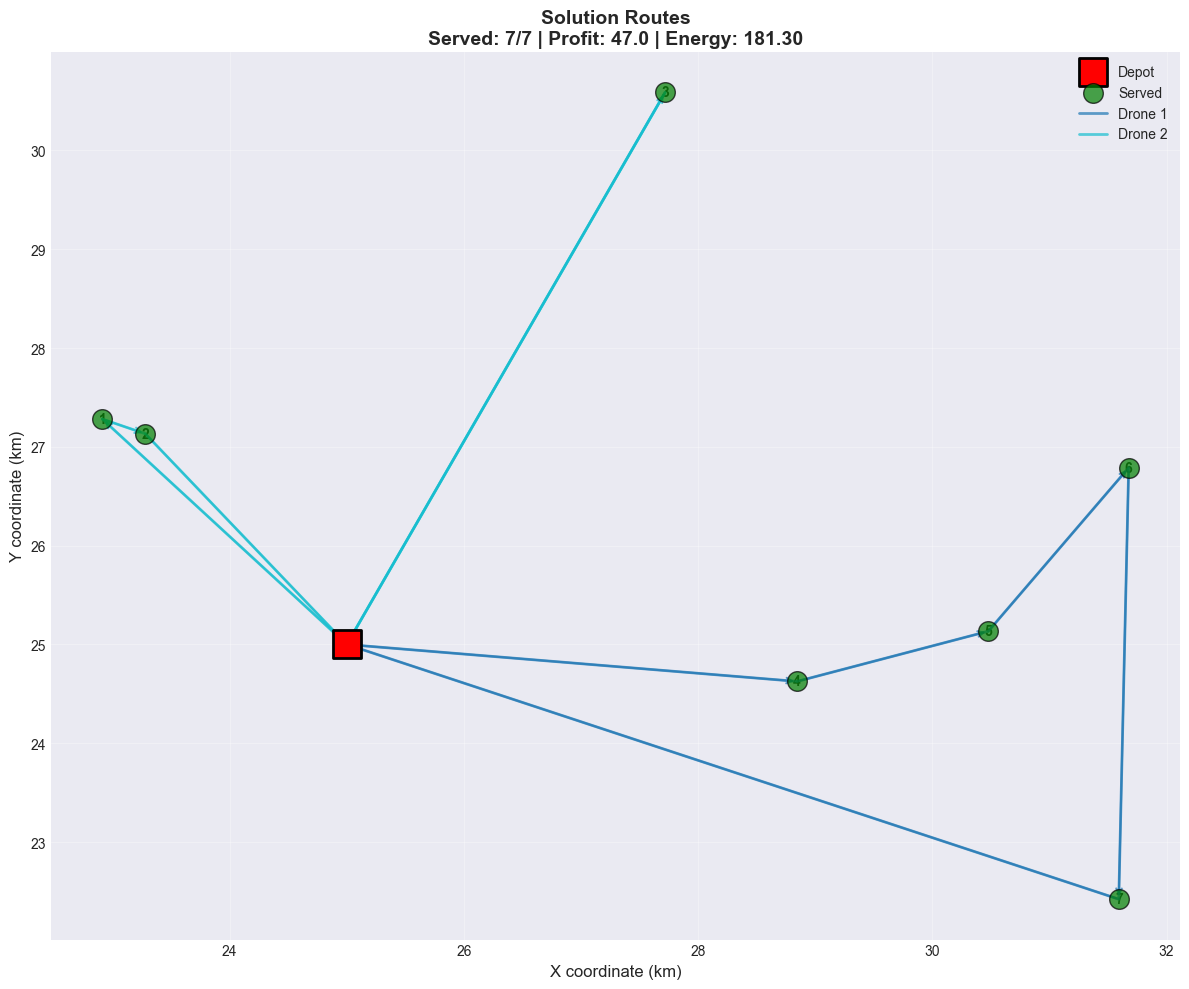


DETAILED SOLUTION

Drone 1:
  Trip 1: 0 → 4 → 5 → 6 → 7 → 0
    Energy consumed: 91.64
    Profit collected: 21.0
  Total energy (drone): 91.64
  Total profit (drone): 21.0

Drone 2:
  Trip 1: 0 → 3 → 0
    Energy consumed: 59.73
    Profit collected: 8.0
  Trip 2: 0 → 1 → 2 → 0
    Energy consumed: 29.94
    Profit collected: 18.0
  Total energy (drone): 89.67
  Total profit (drone): 26.0

SUMMARY
Customers served: 7/7
Total profit: 47.00
Total energy: 181.30
Objective value: 181.30



In [81]:
# ============================================================================
# CELL 12: Test Custom Branch & Bound
# ============================================================================
print("\n" + "="*70)
print("TESTING CUSTOM BRANCH & BOUND")
print("="*70)

bnb_solver = CustomBranchAndBound(preprocessed_medium, config, time_limit=120)
bnb_solution = bnb_solver.solve()

if bnb_solution:
    # Create a new MILP object using the correct instance for visualization
    milp_medium = DroneDeliveryMILP(preprocessed_medium, config)
    milp_medium.visualize_solution(bnb_solution)